# TechStore — First Week Report

Initial SQL report on TechStore's products, stock levels, customer base, orders, and sales targets, followed by a deeper breakdown using `JOIN`s, aggregations, and charts.  
The raw Portuguese database (`SQL/seed_techstore.sql`) is loaded into DuckDB, and an English view layer (`SQL/views_en.sql`) maps table names, columns, and categorical values for reporting.

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect()
con.execute(Path("SQL/seed_techstore.sql").read_text(encoding="utf-8"))
con.execute(Path("SQL/views_en.sql").read_text(encoding="utf-8"))

DOCS_DIR = Path("docs")
DOCS_DIR.mkdir(exist_ok=True)


def sql(query: str):
    """Run a SQL query against the in-memory TechStore database and return a DataFrame."""
    return con.sql(query).df()


sql("""
SELECT table_name, table_type
FROM information_schema.tables
WHERE table_schema = 'main'
ORDER BY table_type, table_name;
""")

,table_name,table_type
0,clientes,BASE TABLE
1,itens_pedido,BASE TABLE
2,pedidos,BASE TABLE
3,produtos,BASE TABLE
4,vendedores,BASE TABLE
5,customers,VIEW
6,order_items,VIEW
7,orders,VIEW
8,products,VIEW
9,sales_reps,VIEW


## 1. Product Catalog

List all products ordered by `category` and `price` (highest first). Show `name`, `category`, `price`, and `stock`.

In [2]:
query = """
SELECT name, category, price, stock
FROM products
ORDER BY category ASC, price DESC;
"""
sql(query)

,name,category,price,stock
0,Teclado Mecanico Pro,Accessories,349.9,150
1,Mouse Gamer RGB,Accessories,189.9,300
2,Adaptador USB-C Hub,Accessories,149.9,200
3,Suporte Notebook Aluminio,Accessories,129.9,85
4,Cabo HDMI 2.1,Accessories,59.9,95
5,Mousepad Gamer XL,Accessories,49.9,110
6,"Pelicula Tablet 10""",Accessories,39.9,150
7,"Capa Notebook 15""",Accessories,29.9,120
8,Notebook Gamer Z5,Laptops,7899.0,8
9,Notebook Pro X1,Laptops,4599.9,45


**Note:** `Laptops` has the highest-priced items (up to R$ 7,899.00 for `Notebook Gamer Z5`), while `Accessories` has the widest variety (8 SKUs) and the highest inventory counts (85–300 units per item).

## 2. Low Stock Items

Find products with fewer than 15 units in stock (`stock < 15`), ordered from lowest to highest stock. Show `name`, `category`, `stock`, and `price`.

In [3]:
query = """
SELECT name, category, stock, price
FROM products
WHERE stock < 15
ORDER BY stock ASC;
"""
sql(query)

,name,category,stock,price
0,"Monitor UltraWide 34""",Monitors,5,2899.0
1,Notebook Gamer Z5,Laptops,8,7899.0
2,Workstation W3,Laptops,12,2599.0


**Note:** Only 3 products fall below 15 units (`Monitor UltraWide 34"` with 5, `Notebook Gamer Z5` with 8, and `Workstation W3` with 12), but all three are high-ticket items (R$ 2,599–R$ 7,899). Running out of stock on these hits revenue much harder than running low on accessories, so they should be first in line for restocking.

## 3. Customer Base by State

List all customers ordered by `state` and `name`. Show `name`, `city`, `state`, and `segment`.

In [4]:
query = """
SELECT name, city, state, segment
FROM customers
ORDER BY state ASC, name ASC;
"""
sql(query)

,name,city,state,segment
0,Prefeitura Regional AM,Manaus,AM,Government
1,Roberto Dias,Manaus,AM,Retail
2,ComTech BA,Salvador,BA,Corporate
3,Roberto Alves,Salvador,BA,Retail
4,Secretaria de Educacao BA,Salvador,BA,Government
5,Beatriz Nogueira,Fortaleza,CE,Retail
6,StartUp XYZ,Brasilia,DF,Corporate
7,Carla Mendonca,Goiania,GO,Retail
8,Ana Oliveira,Belo Horizonte,MG,Retail
9,Camila Santos,Juiz de Fora,MG,Retail


**Note:** Most of the 47 customers are concentrated in the Southeast (`SP`, `RJ`, `MG`), with smaller pockets in the South (`PR`, `RS`, `SC`) and Northeast (`PE`, `BA`, `CE`), and very few accounts in the North and Center-West.

## 4. Government Segment Customers

List customers in the `Government` segment, ordered alphabetically by `name`. Show `name`, `city`, `state`, and `segment`.

In [5]:
query = """
SELECT name, city, state, segment
FROM customers
WHERE segment = 'Government'
ORDER BY name ASC;
"""
sql(query)

,name,city,state,segment
0,Governo MG Edu,Belo Horizonte,MG,Government
1,Governo RJ Digital,Rio de Janeiro,RJ,Government
2,Prefeitura Regional AM,Manaus,AM,Government
3,Prefeitura de Recife,Recife,PE,Government
4,Recife Digital,Recife,PE,Government
5,Secretaria de Educacao BA,Salvador,BA,Government
6,TechGov SP,Sao Paulo,SP,Government


**Note:** There are 7 government accounts spread across 6 states (`AM`, `BA`, `MG`, `PE`, `RJ`, `SP`). Because public-sector procurement usually involves tenders and longer approval cycles, tracking these separately from retail accounts makes sense for forecasting.

## 5. Top 10 Orders by Value

List the 10 largest orders by `total_amount`. Show `id`, `order_date`, `total_amount`, `status`, and `payment_method`.

In [6]:
query = """
SELECT id, order_date, total_amount, status, payment_method
FROM orders
ORDER BY total_amount DESC
LIMIT 10;
"""
sql(query)

,id,order_date,total_amount,status,payment_method
0,34,2024-02-20,12450.0,Delivered,Card
1,67,2024-03-05,8799.9,Delivered,Instant Transfer
2,91,2024-03-11,8799.0,Pending,Card
3,4,2023-12-04,7899.0,Delivered,Card
4,12,2024-01-18,7899.0,Delivered,Card
5,44,2024-02-09,7899.0,Delivered,Card
6,52,2024-02-20,7899.0,Delivered,Card
7,94,2024-03-12,7899.0,Delivered,Card
8,155,2024-03-09,6480.0,Pending,Card
9,41,2024-02-02,5480.0,Cancelled,Card


**Note:** The largest order is `#34` (R$ 12,450.00, paid by Card, Delivered). Worth flagging: two of the top 10 orders (`#91` at R$ 8,799.00 and `#155` at R$ 6,480.00) are still `Pending`, and `#41` (R$ 5,480.00) was `Cancelled`.

## 6. Cancelled Orders

List all orders with `status = 'Cancelled'`, ordered from highest to lowest `total_amount`. Show `id`, `order_date`, `total_amount`, and `payment_method`.

In [7]:
query = """
SELECT id, order_date, total_amount, payment_method
FROM orders
WHERE status = 'Cancelled'
ORDER BY total_amount DESC;
"""
sql(query)

,id,order_date,total_amount,payment_method
0,41,2024-02-02,5480.0,Card
1,132,2024-01-17,4599.0,Card
2,136,2024-03-10,4599.0,Card
3,15,2024-01-10,3299.0,Bank Slip
4,133,2024-01-20,2583.1,Instant Transfer
5,73,2024-03-08,2199.0,Instant Transfer
6,29,2024-01-25,1899.0,Card
7,137,2024-03-12,1899.0,Card
8,138,2024-03-14,1163.0,Bank Slip
9,23,2024-01-15,899.9,Bank Slip


**Note:** There are 12 cancelled orders totaling R$ 28,940.00. Card payments account for 5 of them and 63.8% of the cancelled value (R$ 18,476.00), including the three largest cancellations (`#41`, `#136`, `#132`).

## 7. Sales Reps Above R$ 50,000 Target

List sales reps with a `monthly_target` above R$ 50,000, ordered from highest to lowest target. Show `name`, `region`, and `monthly_target`.

In [8]:
query = """
SELECT name, region, monthly_target
FROM sales_reps
WHERE monthly_target > 50000
ORDER BY monthly_target DESC;
"""
sql(query)

,name,region,monthly_target
0,Ricardo Mendes,Southeast,60000.0
1,Carlos Eduardo,Southeast,55000.0


**Note:** Only 2 of the 7 sales reps have targets above R$ 50,000 — `Ricardo Mendes` (R$ 60,000) and `Carlos Eduardo` (R$ 55,000). Both cover the `Southeast`, which lines up with where most of the customer base is located.

---

# Deeper Analysis (`JOIN`s & Aggregations)

Beyond the initial 7 queries, the cells below combine views to look at rep performance, cancellation rates, category margins, and dead stock.

## 8. Delivered Revenue by Sales Rep

Compare each rep's delivered orders and total revenue (Dec 2023 – Mar 2024, 4 calendar months) against their stated `monthly_target`.

In [9]:
query = """
SELECT
    r.name,
    r.region,
    r.monthly_target,
    COUNT(o.id) AS delivered_orders,
    ROUND(SUM(o.total_amount), 2) AS total_revenue,
    ROUND(SUM(o.total_amount) / 4.0, 2) AS monthly_avg,
    ROUND(100.0 * (SUM(o.total_amount) / 4.0) / r.monthly_target, 1) AS pct_of_target
FROM sales_reps r
LEFT JOIN orders o
    ON o.sales_rep_id = r.id AND o.status = 'Delivered'
GROUP BY r.id, r.name, r.region, r.monthly_target
ORDER BY total_revenue DESC;
"""
df_reps = sql(query)
df_reps

,name,region,monthly_target,delivered_orders,total_revenue,monthly_avg,pct_of_target
0,Ricardo Mendes,Southeast,60000.0,26,69300.3,17325.08,28.9
1,Fernanda Lima,South,45000.0,21,61382.6,15345.65,34.1
2,Juliana Rocha,Northeast,40000.0,20,59480.0,14870.00,37.2
3,Carlos Eduardo,Southeast,55000.0,19,53233.7,13308.42,24.2
4,Marcos Santana,Northeast,35000.0,19,48881.9,12220.48,34.9
5,Amanda Torres,North,30000.0,8,19329.0,4832.25,16.1
6,Bruno Alves,Center-West,35000.0,8,14682.9,3670.72,10.5


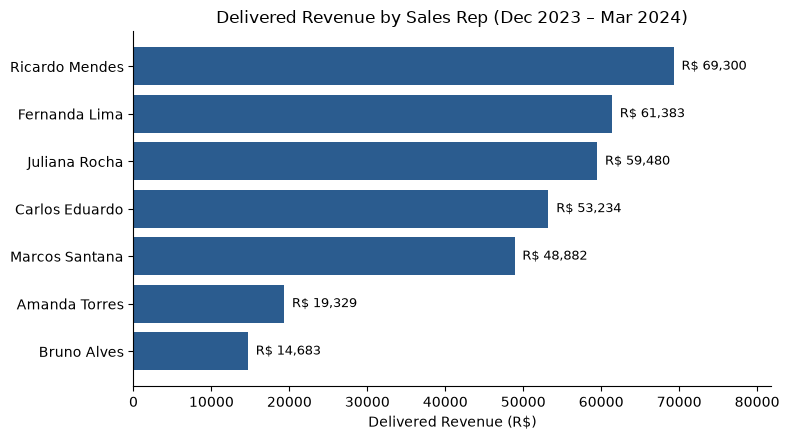

In [10]:
plot_df = df_reps.sort_values("total_revenue", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(plot_df["name"], plot_df["total_revenue"], color="#2b5c8f")
ax.set_xlabel("Delivered Revenue (R$)")
ax.set_title("Delivered Revenue by Sales Rep (Dec 2023 – Mar 2024)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, plot_df["total_revenue"].max() * 1.18)

for bar, val in zip(bars, plot_df["total_revenue"]):
    ax.text(val + 1000, bar.get_y() + bar.get_height() / 2, f"R$ {val:,.0f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(DOCS_DIR / "revenue_by_rep.png", dpi=150)
plt.show()

**Note:** `Ricardo Mendes` leads in total delivered revenue (R$ 69,300.30 across 26 orders), followed by `Fernanda Lima` (R$ 61,382.60) and `Juliana Rocha` (R$ 59,480.00). On a monthly average, no rep reaches 40% of `monthly_target` — either the targets are set well above current demand, or they were intended as quarterly targets rather than monthly ones.

## 9. Cancellation Rate by Payment Method

Compare cancelled order counts, cancellation rate, and cancelled revenue across `Card`, `Bank Slip`, and `Instant Transfer`.

In [11]:
query = """
SELECT
    payment_method,
    COUNT(*) AS total_orders,
    COUNT(*) FILTER (WHERE status = 'Cancelled') AS cancelled_orders,
    ROUND(100.0 * COUNT(*) FILTER (WHERE status = 'Cancelled') / COUNT(*), 1) AS cancellation_rate_pct,
    ROUND(COALESCE(SUM(total_amount) FILTER (WHERE status = 'Cancelled'), 0), 2) AS cancelled_revenue
FROM orders
GROUP BY payment_method
ORDER BY cancelled_revenue DESC;
"""
df_cancel = sql(query)
df_cancel

,payment_method,total_orders,cancelled_orders,cancellation_rate_pct,cancelled_revenue
0,Card,85,5,5.9,18476.0
1,Bank Slip,24,4,16.7,5492.0
2,Instant Transfer,57,3,5.3,4972.0


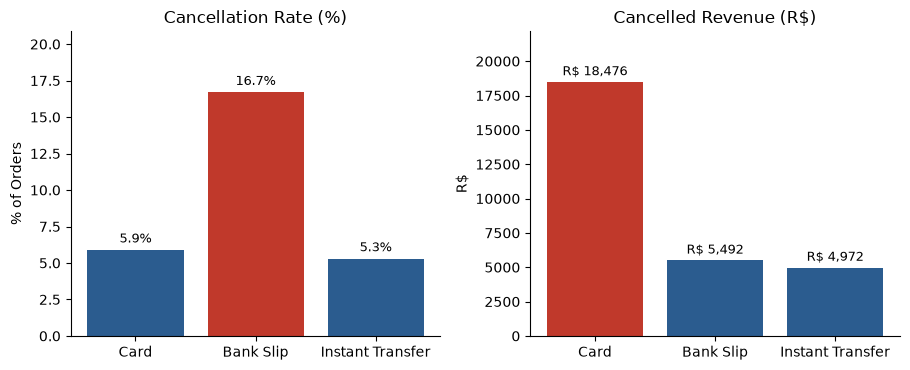

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.8))

rate_colors = ["#c0392b" if m == "Bank Slip" else "#2b5c8f" for m in df_cancel["payment_method"]]
ax1.bar(df_cancel["payment_method"], df_cancel["cancellation_rate_pct"], color=rate_colors)
ax1.set_title("Cancellation Rate (%)")
ax1.set_ylabel("% of Orders")
ax1.set_ylim(0, df_cancel["cancellation_rate_pct"].max() * 1.25)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
for i, val in enumerate(df_cancel["cancellation_rate_pct"]):
    ax1.text(i, val + 0.5, f"{val:.1f}%", ha="center", fontsize=9)

rev_colors = ["#c0392b" if m == "Card" else "#2b5c8f" for m in df_cancel["payment_method"]]
ax2.bar(df_cancel["payment_method"], df_cancel["cancelled_revenue"], color=rev_colors)
ax2.set_title("Cancelled Revenue (R$)")
ax2.set_ylabel("R$")
ax2.set_ylim(0, df_cancel["cancelled_revenue"].max() * 1.2)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
for i, val in enumerate(df_cancel["cancelled_revenue"]):
    ax2.text(i, val + 500, f"R$ {val:,.0f}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(DOCS_DIR / "cancellations_by_payment.png", dpi=150)
plt.show()

**Note:** Looking at volume and value separately tells two different stories: `Card` represents the most lost revenue (R$ 18,476.00) because ticket sizes are larger, but `Bank Slip` has by far the highest cancellation rate at **16.7%** (4 out of 24 orders) — roughly 3x the rate of `Card` (5.9%) and `Instant Transfer` (5.3%). Unpaid bank slip expirations are a common pattern in Brazilian e-commerce.

## 10. Gross Margin and Stock Value by Category

Calculate average gross margin (`(price - cost) / price`) and retail inventory value (`price * stock`) per product category.

In [13]:
query = """
SELECT
    category,
    COUNT(*) AS skus,
    ROUND(AVG((price - cost) / price * 100), 1) AS avg_margin_pct,
    SUM(stock) AS stock_units,
    ROUND(SUM(price * stock), 2) AS retail_stock_value
FROM products
GROUP BY category
ORDER BY avg_margin_pct DESC;
"""
sql(query)

,category,skus,avg_margin_pct,stock_units,retail_stock_value
0,Accessories,8,56.4,1210.0,171229.0
1,Monitors,3,38.5,92.0,112508.0
2,Smartphones,4,36.6,445.0,779055.0
3,Tablets,3,36.3,135.0,249365.0
4,Laptops,5,34.6,128.0,491253.0


**Note:** `Accessories` carries the highest average gross margin (56.4%), while `Laptops` has the lowest (34.6%). Most of the capital tied up in inventory sits in `Smartphones` (R$ 779,055.00) and `Laptops` (R$ 491,253.00).

## 11. Products With Zero Sales

Use a `LEFT JOIN` to find catalog products that have never appeared in `order_items`.

In [14]:
query = """
SELECT
    p.name,
    p.category,
    p.price,
    p.stock,
    ROUND(p.price * p.stock, 2) AS unsold_stock_value
FROM products p
LEFT JOIN order_items oi ON oi.product_id = p.id
WHERE oi.id IS NULL
ORDER BY unsold_stock_value DESC;
"""
sql(query)

,name,category,price,stock,unsold_stock_value
0,Notebook Essencial E2,Laptops,2499.9,45,112495.5
1,"Tablet Essencial 8""",Tablets,1199.0,40,47960.0
2,Adaptador USB-C Hub,Accessories,149.9,200,29980.0
3,Suporte Notebook Aluminio,Accessories,129.9,85,11041.5
4,"Pelicula Tablet 10""",Accessories,39.9,150,5985.0


**Note:** 5 of the 23 catalog products have zero recorded orders. Two of them — `Notebook Essencial E2` (45 units, R$ 112,495.50) and `Tablet Essencial 8"` (40 units, R$ 47,960.00) — account for over R$ 160,000 in unsold inventory value and are worth reviewing for pricing or bundling.